In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from torchgeo_bench.coordbench.config import CoordEvaluationConfig
from torchgeo_bench.coordbench.datasets import load_benchmarks
from torchgeo_bench.coordbench.splits import split_variants, make_folds

In [7]:
bench_era5 = load_benchmarks("era5_ecmwf")[0]
rows = np.arange(len(bench_era5.lat))
STYLE = {"train": ("tab:blue", -0.25), "val": ("tab:green", 0), "test": ("tab:red", 0.25)}

In [50]:
bench_chelsa = load_benchmarks("chelsa_monthly")[0]
rows = np.arange(len(bench_chelsa.lat))
STYLE = {"train": ("tab:blue", -0.25), "val": ("tab:green", 0), "test": ("tab:red", 0.25)}

/home/libe2152/projects/torchgeo-bench/src/torchgeo_bench/coordbench/datasets.py:394: RuntimeWarning: divide by zero encountered in log
  tasks[f"{task_name}_log"] = np.log(df[task_name].to_numpy(np.float64))
/home/libe2152/projects/torchgeo-bench/src/torchgeo_bench/coordbench/datasets.py:394: RuntimeWarning: divide by zero encountered in log
  tasks[f"{task_name}_log"] = np.log(df[task_name].to_numpy(np.float64))
/home/libe2152/projects/torchgeo-bench/src/torchgeo_bench/coordbench/datasets.py:394: RuntimeWarning: invalid value encountered in log
  tasks[f"{task_name}_log"] = np.log(df[task_name].to_numpy(np.float64))


In [ ]:
def plot_split(bench, split, cfg):
    rows = np.arange(len(bench.lat))
    dates = pd.to_datetime(bench.posix_timestamp, unit="s")
    for outer, inner, time_unit in split_variants(cfg):
        if outer != split:
            continue
        folds = make_folds(cfg, bench, rows, seed=0, variant=(outer, inner, time_unit))
        unit, size = time_unit or (None, None)

        panels = []
        for k, f in enumerate(folds):
            panels.append((f"outer {k}", {"train": f.train, "test": f.test}))
            #panels += [(f"{k}.inner {j}", {"train": tr, "val": va, "test": f.test}) for j, (tr, va) in enumerate(f.inner)]

        gap_outer = 2
        #gap_inner = 2

        ys = []
        offset = 0

        for i, (name, _) in enumerate(panels):
            if i > 0 and name.startswith("outer"):
                offset += gap_outer
            ys.append(offset)
            #ys.append(i * gap_inner + offset)

        fig, ax = plt.subplots(figsize=(15, 0.4 * max(ys) + 2))

        height = 0.5

        for y, (_, roles) in zip(ys, panels):
            for role, idx in roles.items():
                d = dates[idx].unique()
                pos = y + STYLE[role][1] * 1  # spread train/val/test apart

                ax.vlines(
                    d, pos - height / 2, pos + height / 2,
                    colors=STYLE[role][0],
                    linewidth=4,
                    alpha=0.9,
                )

        ax.set_yticks(ys, [name for name, _ in panels])
        ax.invert_yaxis()

        ax.grid(axis="y", alpha=0.15)
        ax.spines[["top", "right"]].set_visible(False)

        #ax.set_title(f"Outer: {outer} | Inner: {inner} | Time: {size} {unit}")
        ax.set_title(f"Outer: {outer} | Time: {size} {unit}")
        ax.set_title(f"Outer: {outer} | Inner: {inner} | Time: {size} {unit}")
        ax.legend(handles=[Patch(color=color, label=role) for role, (color, _) in STYLE.items()],
                  loc="upper left", bbox_to_anchor=(1, 1))

        plt.show()

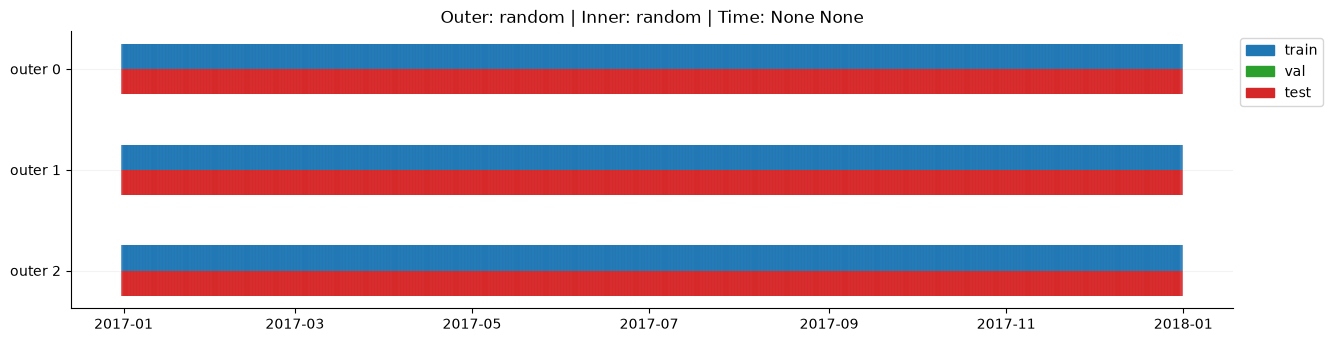

In [52]:
split = "random"
cfg = CoordEvaluationConfig(nested_splits=[(split, split)], folds=3, inner_folds=3)
plot_split(bench_era5, split, cfg)

In [53]:
f = make_folds(cfg, bench_era5, rows, seed=0, variant=(split, split, None))[0]; tr, va = f.inner[0]
print(len(tr), len(va), np.intersect1d(tr, va).size)  # last number should be 0


448000 224000 0


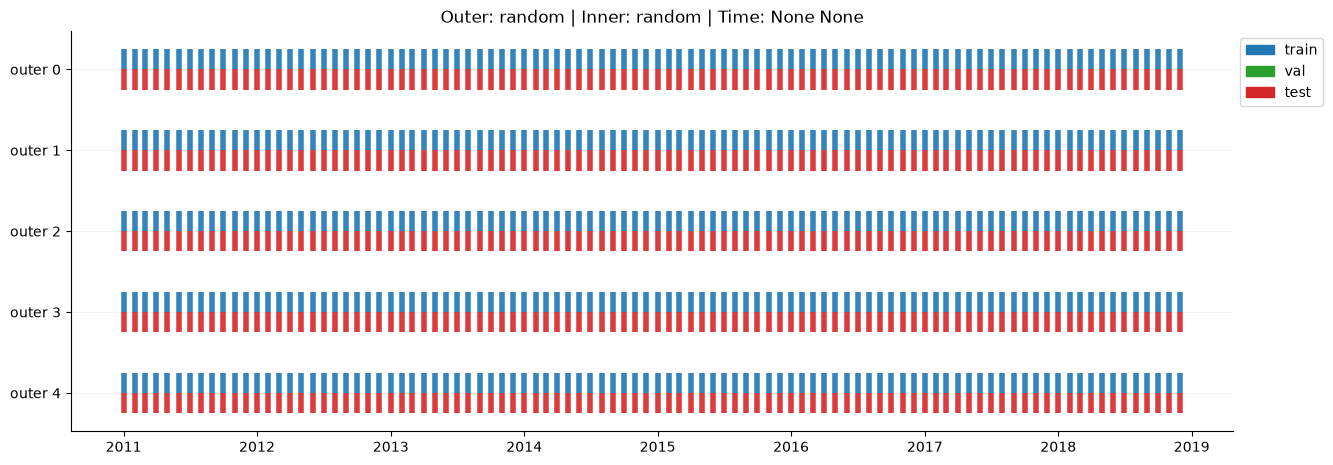

In [54]:
split = "random"
cfg = CoordEvaluationConfig(nested_splits=[(split, split)], folds=5, inner_folds=3)
plot_split(bench_chelsa, split, cfg)

# Temporal Splits

## Temporal Forecast

### With random inner split

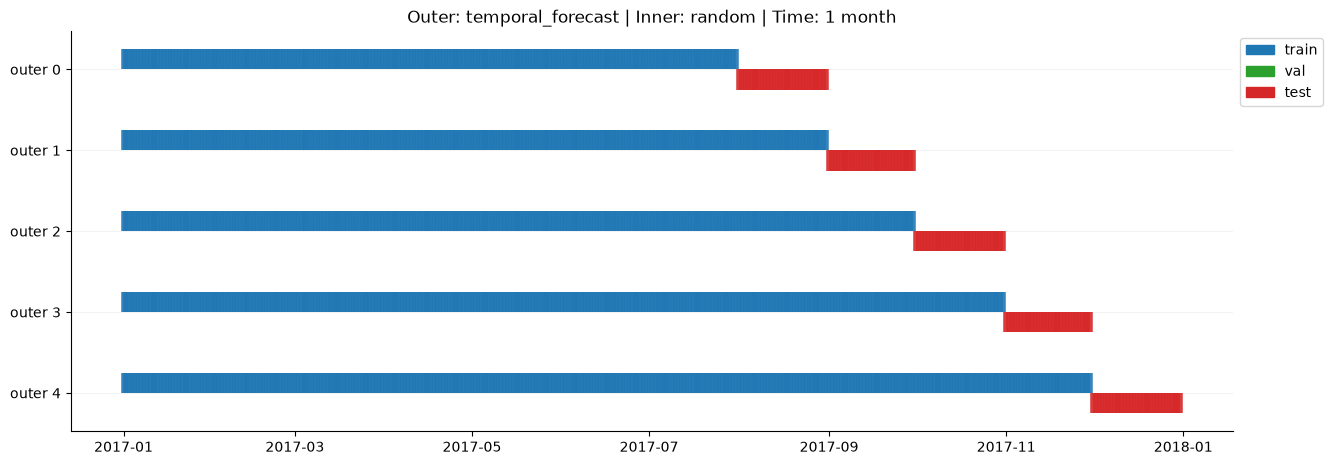

In [55]:
split = "temporal_forecast"
cfg = CoordEvaluationConfig(nested_splits=[(split, "random")], folds=5, inner_folds=3, time_units=[("month", 1)], test_size=1)
plot_split(bench_era5, split, cfg)

## Temporal Checkerboard

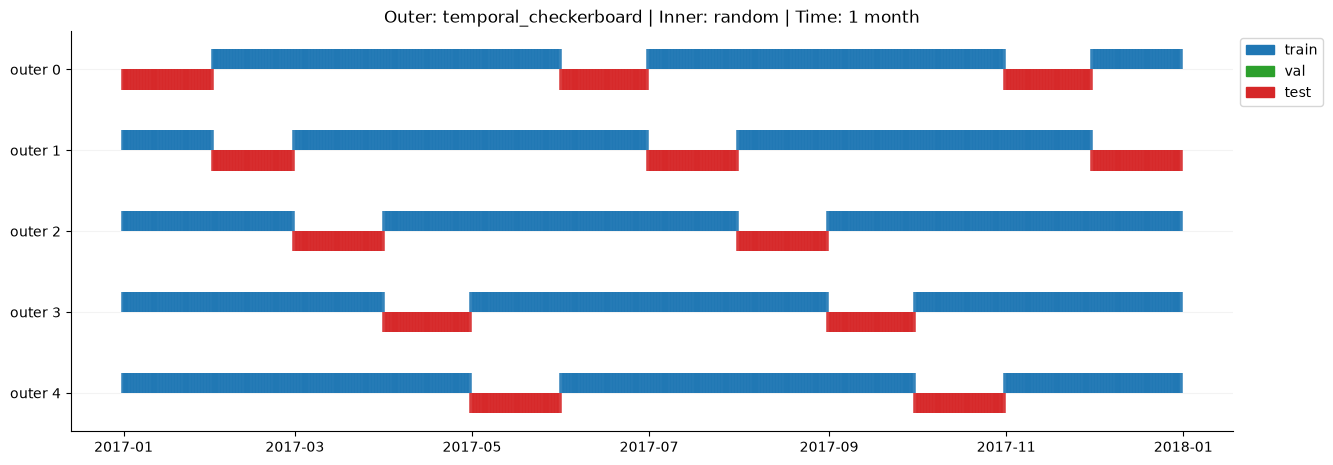

In [56]:
split = "temporal_checkerboard"
cfg = CoordEvaluationConfig(nested_splits=[(split, "random")], folds=5, inner_folds=3, time_units=[("month", 1)])
plot_split(bench_era5, split, cfg)

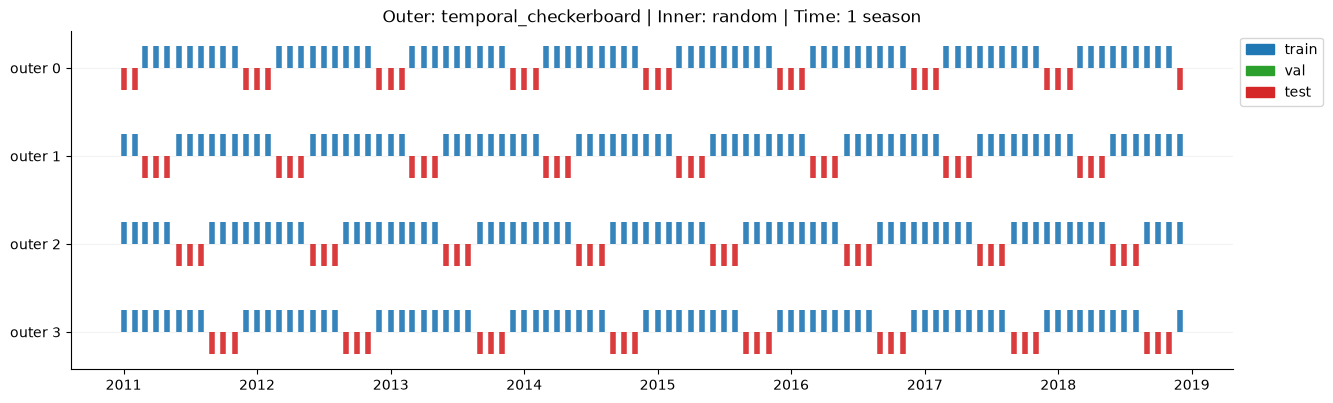

In [57]:
split = "temporal_checkerboard"
cfg = CoordEvaluationConfig(nested_splits=[(split, "random")], folds=4, inner_folds=3, time_units=[("season", 1)])
plot_split(bench_chelsa, split, cfg)

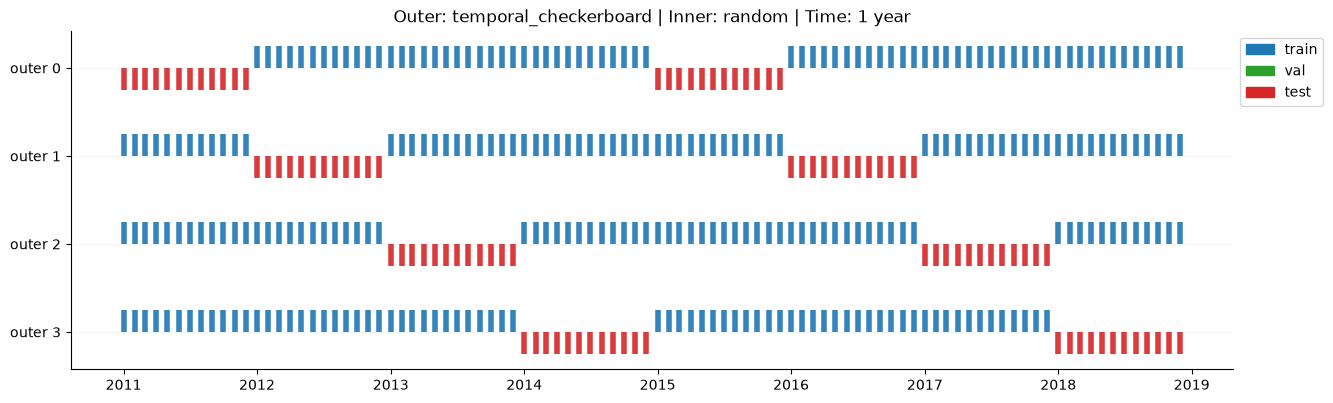

In [58]:
split = "temporal_checkerboard"
cfg = CoordEvaluationConfig(nested_splits=[(split, "random")], folds=4, inner_folds=3, time_units=[("year", 1)])
plot_split(bench_chelsa, split, cfg)

## With Blocking (fixed train size)

## Temporal Forecast Block

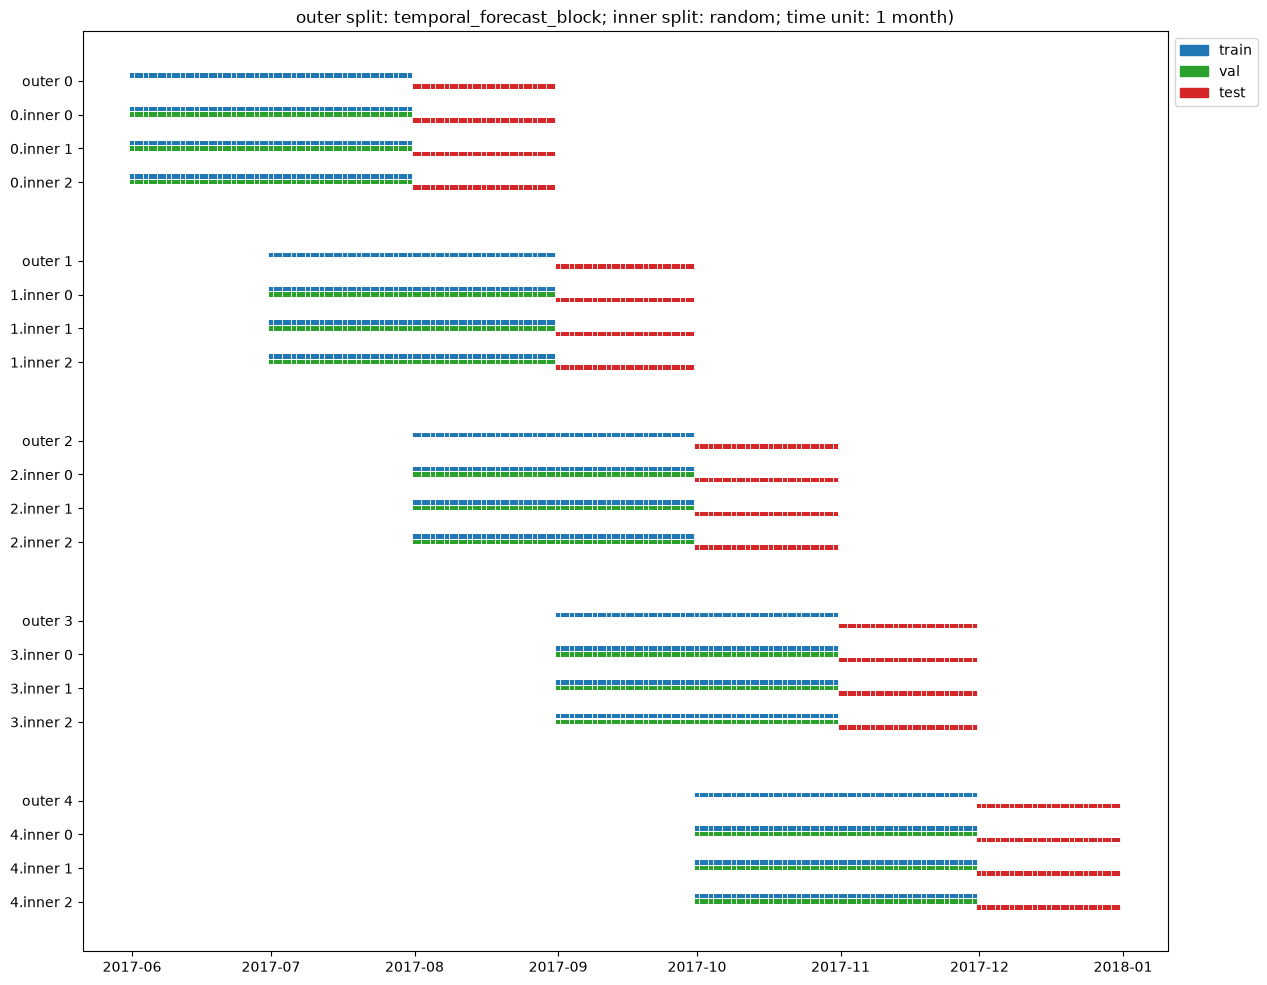

In [22]:
split = "temporal_forecast_block"
cfg = CoordEvaluationConfig(nested_splits=[(split, "random")], folds=5, inner_folds=3, time_units=[("month", 1)], max_train_size=2, test_size=1)
plot_split(bench_era5, split, cfg)

## Temporal Contiguous Block

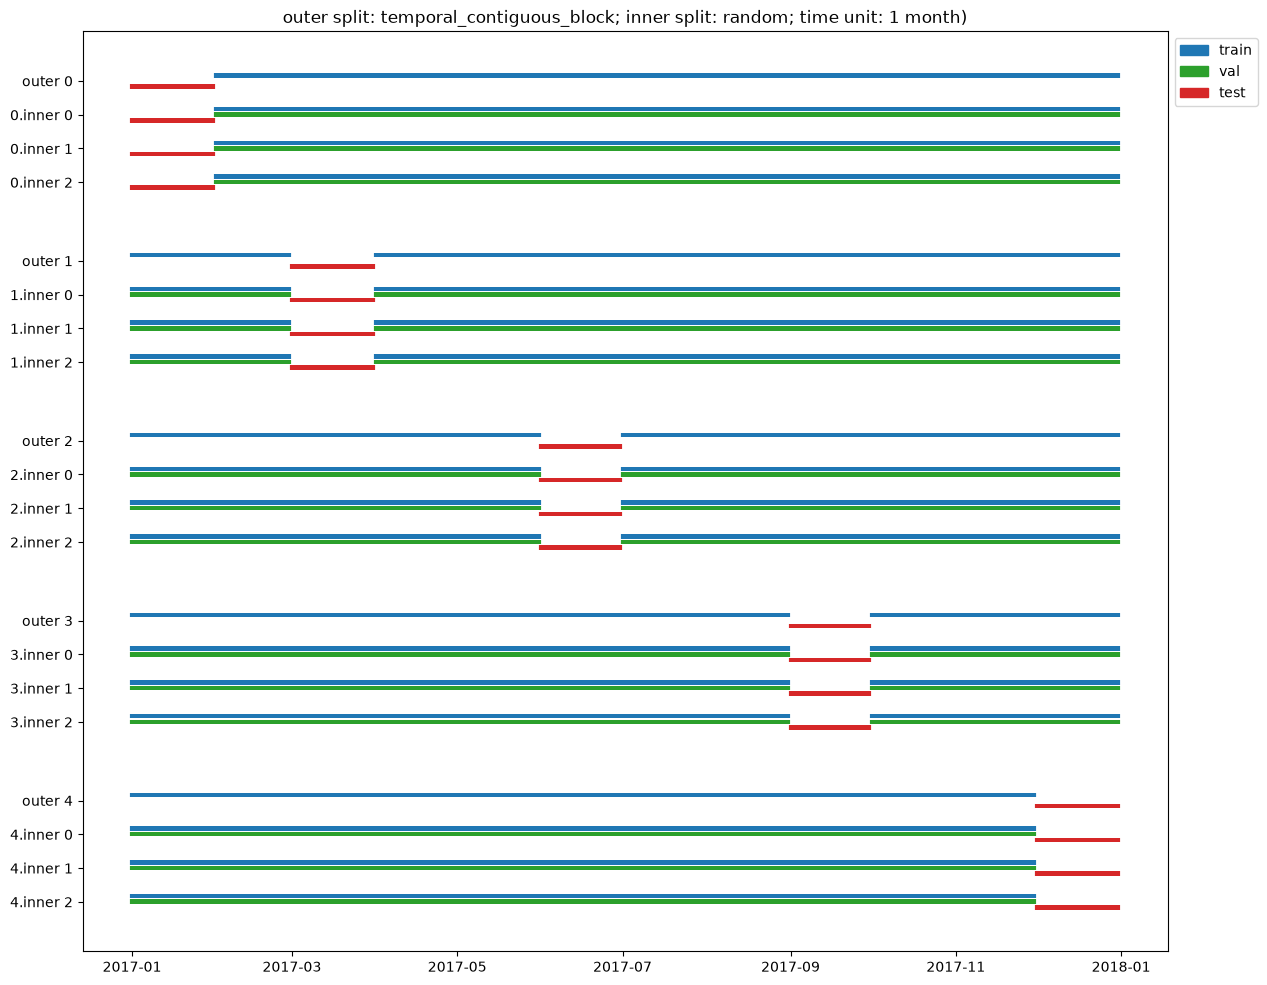

In [23]:
split = "temporal_contiguous_block"
cfg = CoordEvaluationConfig(nested_splits=[(split, "random")], folds=5, inner_folds=3, time_units=[("month", 1)])
plot_split(bench_era5, split, cfg)

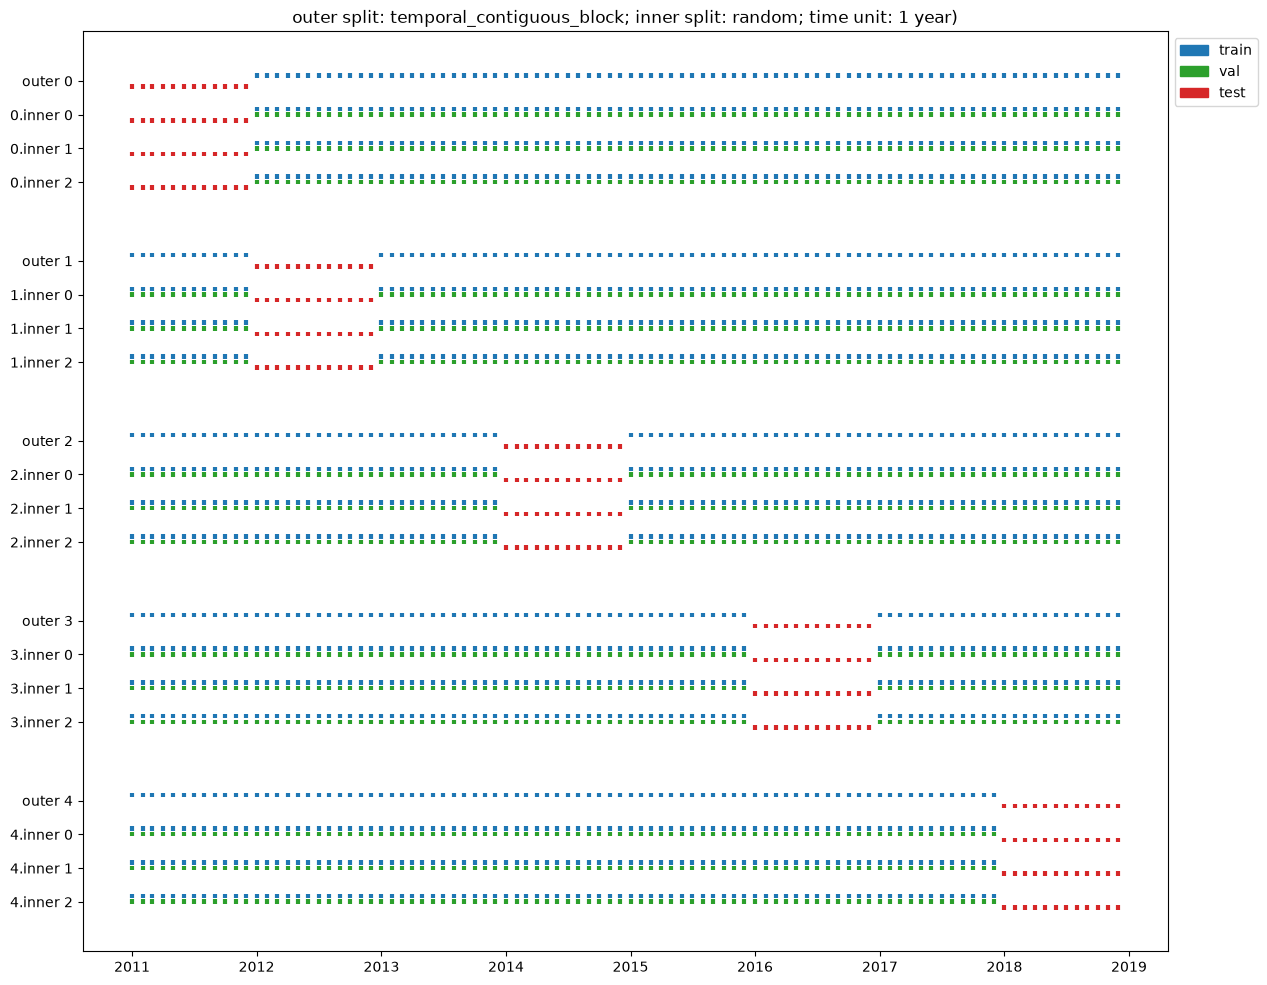

In [24]:
split = "temporal_contiguous_block"
cfg = CoordEvaluationConfig(nested_splits=[(split, "random")], folds=5, inner_folds=3, time_units=[("year", 1)])
plot_split(bench_chelsa, split, cfg)